# 14장 실습. 분산 학습: GRPO·소프트 교차 엔트로피

13장의 교사 분포로 Laya multilingual 을 파인튜닝한다. 손실은 둘이다.

| 손실 | 무엇을 하나 |
|---|---|
| soft CE (`soft-ce`) | 교사 분포와의 교차 엔트로피. 분포를 그대로 흉내 낸다 |
| RLCD (`rlcd`, Laya 기본값) | soft CE + GRPO 식 정책 경사. 로짓에 잡음을 섞은 표본 넷을 뽑고, 적절한 점수 규칙(spherical·RPS)으로 매긴 보상의 상대값으로 갱신한다 |

| 절 | 내용 |
|---|---|
| 14.1 | 두 손실을 작은 텐서로 들여다본다 |
| 14.2 | 학습 예산 — optimizer 갱신 횟수 |
| 14.3 | 한 장치에서 파인튜닝 (`laya.train.finetune`) — 기본 경로 |
| 14.4 | 파인튜닝한 체크포인트를 평가셋으로 잰다 |
| 14.5 | 여러 GPU — `torchrun` 과 DDP (선택) |

GPU 한 장이면 실행마다 몇 분이다. GPU 가 없으면 과제마다 150건, 1 epoch 의 빠른 모드로 돈다. 빠른 모드는 코드가 끝까지 도는지 확인하는 용도이고 숫자는 책에 쓰지 않는다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_setup → nb08_evaluation 을 먼저 실행한다"

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

import laya

def checkpoint_engine(path, **load_kwargs):
    agent = laya.load(str(path), **load_kwargs)
    def post(state, questions):
        t0 = time.perf_counter()
        r = agent.predict(state, questions)
        return r | {"model": "laya:" + Path(path).name, "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
    post.agent = agent
    return post

import torch, subprocess, sys
from laya.train import TrainConfig, finetune, optimizer_updates, rlcd_loss, soft_ce_loss

TRAIN, MODELS, RESULTS = DATA / "train", Path("models"), Path("results/eval_v1")
MODELS.mkdir(exist_ok=True)
write_jsonl = lambda p, rows: Path(p).write_text("".join(json.dumps(r, ensure_ascii=False, default=str) + "\n" for r in rows), encoding="utf-8")
FULL = torch.cuda.is_available()
print("장치:", torch.cuda.get_device_name(0) if FULL else "CPU", "| 모드:", ["빠른 모드", "전체"][FULL])

장치: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition | 모드: 전체


## 14.1 손실 함수: soft CE 대 RLCD

선택지 넷인 질문 하나를 생각한다. 교사 분포는 [0.6, 0.3, 0.1, 0.0] 이다. 로짓 네 개만 파라미터로 두고, 두 손실로 각각 300번 경사 하강한다. 같은 목표 분포에 도달하는지, 얼마나 빨리 가는지 본다.

In [2]:
target = torch.tensor([[0.6, 0.3, 0.1, 0.0]])
mask, qtype = torch.ones(1, 4, dtype=torch.bool), torch.tensor([0])        # 0 = choice

def descend(loss_fn, steps=300, lr=0.1, seed=0):
    torch.manual_seed(seed)
    z = torch.zeros(1, 4, requires_grad=True)
    opt = torch.optim.SGD([z], lr=lr)
    trace = []
    for _ in range(steps):
        opt.zero_grad(); loss_fn(z).backward(); opt.step()
        trace.append(torch.softmax(z.detach(), -1)[0].numpy().copy())
    return np.array(trace)

traces = {"soft CE": descend(lambda z: soft_ce_loss(z, target, mask)),
          "RLCD (σ=0.4, 표본 4)": descend(lambda z: rlcd_loss(z, target, mask, qtype, sigma=0.4))}
tv = lambda tr: 0.5 * np.abs(tr - target[0].numpy()).sum(-1)
pd.DataFrame({name: {"최종 분포": tr[-1].round(3).tolist(), "목표와 TV 거리": tv(tr[-1]), "TV < 0.05 에 닿은 걸음": int(np.argmax(tv(tr) < 0.05))}
              for name, tr in traces.items()}).T

,최종 분포,목표와 TV 거리,TV < 0.05 에 닿은 걸음
soft CE,"[0.5929999947547913, 0.2919999957084656, 0.093...",0.023,119
"RLCD (σ=0.4, 표본 4)","[0.6380000114440918, 0.24899999797344208, 0.11...",0.051,11


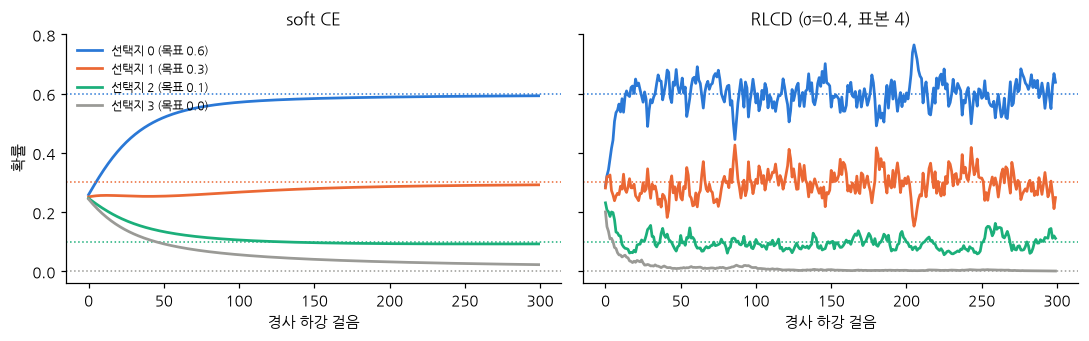

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), dpi=110, sharey=True)
for ax, (name, tr) in zip(axes, traces.items()):
    for j, c in enumerate(["#2a78d6", "#eb6834", "#1baf7a", "#9a9a96"]):
        ax.plot(tr[:, j], color=c, lw=1.8, label=f"선택지 {j} (목표 {target[0, j]:.1f})"); ax.axhline(target[0, j], color=c, ls=":", lw=1)
    ax.set_title(name, fontsize=11); ax.set_xlabel("경사 하강 걸음")
axes[0].set_ylabel("확률"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "nb14_loss_toy.png", bbox_inches="tight"); plt.show()

## 14.2 optimizer 갱신 예산

학습량을 정하는 숫자는 epoch 가 아니라 optimizer 갱신 횟수다. 갱신 횟수 = epoch × ⌈⌈학습 항목 / micro_batch⌉ / grad_accum⌉. 학습 항목은 보정 조각(최대 400건 또는 10%)을 뺀 수다.

In [4]:
pd.DataFrame([{"학습 항목": n, "epoch": e, "갱신 횟수": optimizer_updates(n, 8, 8, e)} for n in (540, 1350, 5600) for e in (2, 4, 8)]
             ).pivot(index="학습 항목", columns="epoch", values="갱신 횟수")

epoch,2,4,8
학습 항목,,,
540,18,36,72
1350,44,88,176
5600,176,352,704


## 14.3 단일 장치 파인튜닝

`laya.train.finetune(데이터, 시작 체크포인트, 저장 위치, TrainConfig)` 이 한 번에 한다. 항목 만들기 → 보정 조각 떼어 두기 → 학습 → 보정 조각으로 질문 유형별 온도 맞추기 → 저장. 교사와 손실을 바꿔 넷을 돌린다.

| 실행 | 교사 | 손실 | 무엇을 보나 |
|---|---|---|---|
| `softce-human` | human | soft CE | 손실의 차이 (rlcd-human 과 짝) |
| `rlcd-human` | human | RLCD | 기준 |
| `rlcd-mix` | mix (Jev + 사람) | RLCD | 외부 교사를 섞으면 |
| `rlcd-llm` | llm (로컬 LLM) | RLCD | 사내 교사만으로 |

In [5]:
RUNS = {"softce-human": ("human", "soft-ce"), "rlcd-human": ("human", "rlcd"), "rlcd-mix": ("mix", "rlcd"), "rlcd-llm": ("llm", "rlcd")}

def training_file(teacher):
    # 빠른 모드는 과제마다 앞 150건만 쓴다
    rows = read_jsonl(TRAIN / f"{teacher}.jsonl")
    keep = [r for t in TASKS for r in [x for x in rows if x["task"] == t][: [150, None][FULL]]]
    (MODELS / "_data").mkdir(exist_ok=True)
    write_jsonl(MODELS / "_data" / f"{teacher}.jsonl", keep)
    return str(MODELS / "_data" / f"{teacher}.jsonl")

reports = {}
for name, (teacher, loss) in RUNS.items():
    t0 = time.perf_counter()
    rep = finetune(training_file(teacher), "multilingual", str(MODELS / name), TrainConfig(loss=loss, epochs=[1, 4][FULL], seed=0))
    reports[name] = {"교사": teacher, "손실": loss, "학습 항목": rep["train_items"], "보정 항목": rep["calibration_items"],
                     "epoch 손실": [round(x, 4) for x in rep["epoch_loss"]], "온도 (choice, score, noul)": [round(x, 3) for x in rep["temperature"]],
                     "시간(초)": time.perf_counter() - t0}
pd.DataFrame(reports).T

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2182.71it/s]


train items 5600, calibration items 400, eval items 400 (calibration_slice), skipped {}, device cuda:0
optimizer budget: 5600 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 352 optimizer updates over 4 epoch(s)
epoch 1/4 step 100 loss 0.7262
epoch 1/4 step 200 loss 1.0069
epoch 1/4 step 300 loss 0.6532
epoch 1/4 step 400 loss 0.6949
epoch 1/4 step 500 loss 0.4795
epoch 1/4 step 600 loss 0.4601
epoch 1/4 step 700 loss 0.3330
epoch 1/4 mean loss 0.7123
epoch 2/4 step 100 loss 1.0843
epoch 2/4 step 200 loss 0.5620
epoch 2/4 step 300 loss 0.9064
epoch 2/4 step 400 loss 0.2460
epoch 2/4 step 500 loss 0.3371
epoch 2/4 step 600 loss 0.2913
epoch 2/4 step 700 loss 0.4892
epoch 2/4 mean loss 0.4635
epoch 3/4 step 100 loss 0.3678
epoch 3/4 step 200 loss 0.5013
epoch 3/4 step 300 loss 0.3250
epoch 3/4 step 400 loss 0.6892
epoch 3/4 step 500 loss 0.1615
epoch 3/4 step 600 loss 0.2338
epoch 3/4 step 700 loss 0.7867
epoch 3/4 mean loss 0.3583
epoch 4/4 step 100 loss 0.3958
e

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2119.83it/s]


train items 5600, calibration items 400, eval items 400 (calibration_slice), skipped {}, device cuda:0
optimizer budget: 5600 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 352 optimizer updates over 4 epoch(s)


/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/laya/train.py:724: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


...

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2237.44it/s]


train items 5600, calibration items 400, eval items 400 (calibration_slice), skipped {}, device cuda:0
optimizer budget: 5600 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 352 optimizer updates over 4 epoch(s)
epoch 1/4 step 100 loss 0.4500
epoch 1/4 step 200 loss 0.9618
epoch 1/4 step 300 loss -0.2971
epoch 1/4 step 400 loss 0.3998
epoch 1/4 step 500 loss 0.4672
epoch 1/4 step 600 loss -0.2630
epoch 1/4 step 700 loss 0.6906
epoch 1/4 mean loss 0.5902
epoch 2/4 step 100 loss 0.7390
epoch 2/4 step 200 loss 0.5875
epoch 2/4 step 300 loss 0.8823
epoch 2/4 step 400 loss 0.3673
epoch 2/4 step 500 loss 0.5169
epoch 2/4 step 600 loss 0.4182
epoch 2/4 step 700 loss 0.6493
epoch 2/4 mean loss 0.4500
epoch 3/4 step 100 loss 0.0271
epoch 3/4 step 200 loss 0.2201
epoch 3/4 step 300 loss 0.1602
epoch 3/4 step 400 loss 1.2825
epoch 3/4 step 500 loss 0.3080
epoch 3/4 step 600 loss 0.8422
epoch 3/4 step 700 loss 0.3548
epoch 3/4 mean loss 0.4357
epoch 4/4 step 100 loss 0.7462

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2144.11it/s]


train items 5600, calibration items 400, eval items 400 (calibration_slice), skipped {}, device cuda:0
optimizer budget: 5600 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 352 optimizer updates over 4 epoch(s)
epoch 1/4 step 100 loss 0.4588
epoch 1/4 step 200 loss 0.8070
epoch 1/4 step 300 loss -0.1731
epoch 1/4 step 400 loss 0.7362
epoch 1/4 step 500 loss 0.2902
epoch 1/4 step 600 loss 0.4330
epoch 1/4 step 700 loss 0.4452
epoch 1/4 mean loss 0.6249
epoch 2/4 step 100 loss 0.5077
epoch 2/4 step 200 loss 0.2370
epoch 2/4 step 300 loss 0.4244
epoch 2/4 step 400 loss 0.6053
epoch 2/4 step 500 loss 0.6881
epoch 2/4 step 600 loss 0.8787
epoch 2/4 step 700 loss 0.2855
epoch 2/4 mean loss 0.4767
epoch 3/4 step 100 loss 0.7455
epoch 3/4 step 200 loss 0.4529
epoch 3/4 step 300 loss 0.0321
epoch 3/4 step 400 loss 1.3839
epoch 3/4 step 500 loss 0.0664
epoch 3/4 step 600 loss 0.5413
epoch 3/4 step 700 loss 0.3230
epoch 3/4 mean loss 0.4751
epoch 4/4 step 100 loss 0.6691


,교사,손실,학습 항목,보정 항목,epoch 손실,"온도 (choice, score, noul)",시간(초)
softce-human,human,soft-ce,5600,400,"[0.7123, 0.4635, 0.3583, 0.3126]","[1.51, 1.438, 2.783]",249.628
rlcd-human,human,rlcd,5600,400,"[0.6167, 0.4308, 0.3856, 0.3582]","[1.444, 1.215, 2.633]",254.172
rlcd-mix,mix,rlcd,5600,400,"[0.5902, 0.45, 0.4357, 0.4332]","[1.133, 1.215, 1.359]",255.245
rlcd-llm,llm,rlcd,5600,400,"[0.6249, 0.4767, 0.4751, 0.4975]","[1.275, 1.12, 1.251]",255.25


## 14.4 파인튜닝 모델 평가

체크포인트를 열어 8장의 채점 함수에 꽂는다. 기록은 `laya-ft-<실행>` 으로 남기고 12장의 Laya 기본·Jev 와 같은 표에 놓는다.

In [6]:
items = read_jsonl(DATA / "eval_v1.jsonl")
for name in RUNS:
    post = checkpoint_engine(MODELS / name)
    write_jsonl(RESULTS / f"laya-ft-{name}.records.jsonl", run(items, engine=lambda it: post(it["state"], it["questions"]), workers=1))

def coverage_at_risk(conf, ok, risk=0.05):
    order = np.argsort(-conf, kind="stable")
    c, y, k = conf[order], ok[order], np.arange(1, len(conf) + 1)
    return float(np.max(k[np.append(c[1:] != c[:-1], True) & (np.cumsum(1 - y) / k <= risk)], initial=0) / len(conf))

summarize = lambda rs: {"accuracy": arrays(rs)[1].mean(), "mean_conf": arrays(rs)[0].mean(), "ece": ece(*arrays(rs)), "coverage@5%": coverage_at_risk(*arrays(rs))}
names = ["jev", "laya-routed", *[f"laya-ft-{k}" for k in RUNS]]
recs = {n: read_jsonl(RESULTS / f"{n}.records.jsonl") for n in names}
pd.DataFrame([{"과제": t, "엔진": n, **summarize([r for r in recs[n] if r["task"] == t or t == "ALL"])} for t in TASKS + ["ALL"] for n in names]).set_index(["과제", "엔진"])

accuracy  mean_conf    ece  coverage@5%
과제         엔진                                                           
topic      jev                      0.800      0.897  0.102        0.565
           laya-routed              0.340      0.663  0.323        0.000
           laya-ft-softce-human     0.745      0.714  0.087        0.300
           laya-ft-rlcd-human       0.745      0.704  0.063        0.045
           laya-ft-rlcd-mix         0.745      0.707  0.089        0.065
           laya-ft-rlcd-llm         0.670      0.707  0.059        0.035
entails    jev                      0.975      0.919  0.061        1.000
           laya-routed              0.880      0.948  0.110        0.550
           laya-ft-softce-human     0.895      0.797  0.098        0.760
           laya-ft-rlcd-human       0.870      0.830  0.069        0.745
           laya-ft-rlcd-mix         0.890      0.877  0.036        0.765
           laya-ft-rlcd-llm         0.885      0.809  0.077        0.525
positive   jev                      0.850      0.831  0.036        0.665
           laya-routed              0.665      0.779  0.146        0.005
           laya-ft-softce-human     0.800      0.844  0.060        0.470
           laya-ft-rlcd-human       0.775      0.841  0.078        0.335
           laya-ft-rlcd-mix         0.800      0.796  0.079        0.445
           laya-ft-rlcd-llm         0.795      0.830  0.063        0.225
similarity jev                      0.350      0.621  0.275        0.005
           laya-routed              0.140      0.328  0.188        0.000
           laya-ft-softce-human     0.470      0.441  0.062        0.000
           laya-ft-rlcd-human       0.470      0.439  0.072        0.005
           laya-ft-rlcd-mix         0.480      0.418  0.094        0.015
           laya-ft-rlcd-llm         0.310      0.400  0.121        0.020
ALL        jev                      0.744      0.817  0.073        0.507
           laya-routed              0.506      0.679  0.173        0.126
           laya-ft-softce-human     0.728      0.699  0.044        0.250
           laya-ft-rlcd-human       0.715      0.703  0.027        0.165
           laya-ft-rlcd-mix         0.729      0.700  0.049        0.367
           laya-ft-rlcd-llm         0.665      0.687  0.059        0.083

## 14.5 DDP 다중 GPU 학습 (선택)

`scripts/train_ddp.py` 는 같은 학습을 GPU 여러 장에 나눈다. 프로세스마다 모델 사본을 하나씩 두고, 학습 항목을 rank 수로 나눠 각자 forward·backward 를 한 뒤 기울기를 all-reduce 로 평균한다. 보정 조각은 나누기 전에 모든 rank 가 같게 떼어 두고, 온도 맞추기와 저장은 rank 0 만 한다.

2판에서 잰 DDP 는 GPU 두 장이 한 장보다 두 배 가까이 느렸다. 기울기를 네 걸음 모으는 동안에도 걸음마다 GPU 사이 동기화를 했기 때문이다. 이 판의 스크립트는 갱신 직전에만 동기화하고(`no_sync`), 토큰화를 학습 전에 한 번만 한다.

GPU 가 둘 이상일 때만 실제로 돌고, 아니면 명령만 보여 준다. 끝나면 단일 장치의 rlcd-human 과 시간·정확도를 견준다.

In [7]:
n_gpu = torch.cuda.device_count()
cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={max(n_gpu, 2)}",
       "scripts/train_ddp.py", training_file("human"), "multilingual", str(MODELS / "ddp-human"), "--loss", "rlcd", "--grad-accum", "4"]
print(" ".join(cmd))
done = [subprocess.run(cmd, check=True) for _ in range(n_gpu >= 2)]          # GPU 가 둘 이상일 때만 한 번 돈다

/home/josh/anaconda3/envs/pytorch/bin/python -m torch.distributed.run --standalone --nproc_per_node=2 scripts/train_ddp.py models/_data/human.jsonl multilingual models/ddp-human --loss rlcd --grad-accum 4



*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2651.27it/s]


학습 5600건 (rank 당 2800), 보정 400건, 건너뜀 {}, GPU 2개, 손실 rlcd


[rank0]:[W1016 22:22:48.968597827 reducer.cpp:1528] Warning: find_unused_parameters=True was specified in DDP constructor, but did not find any unused parameters in the forward pass. This flag results in an extra traversal of the autograd graph every iteration,  which can adversely affect performance. If your model indeed never has any unused parameters in the forward pass, consider turning this flag off. Note that this warning may be a false positive if your model has flow control causing later iterations to have unused parameters. (function operator())
[rank1]:[W1016 22:22:48.974415055 reducer.cpp:1528] Warning: find_unused_parameters=True was specified in DDP constructor, but did not find any unused parameters in the forward pass. This flag results in an extra traversal of the autograd graph every iteration,  which can adversely affect performance. If your model indeed never has any unused parameters in the forward pass, consider turning this flag off. Note that this warning may be 

epoch 1/4  평균 손실 0.6370  58초


/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


epoch 2/4  평균 손실 0.4471  115초
epoch 3/4  평균 손실 0.3571  173초
epoch 4/4  평균 손실 0.3689  228초
저장: models/ddp-human | 온도 (choice, score, noul): [1.463, 1.209, 2.627]


In [8]:
ddp = json.loads((MODELS / "ddp-human" / "train_ddp.json").read_text())
post = checkpoint_engine(MODELS / "ddp-human")
ddp_rec = run(items, engine=lambda it: post(it["state"], it["questions"]), workers=1)
write_jsonl(RESULTS / "laya-ft-ddp-human.records.jsonl", ddp_rec)
pd.DataFrame({"단일 장치 rlcd-human": {"GPU": 1, "시간(초)": reports["rlcd-human"]["시간(초)"], "정확도": summarize(recs["laya-ft-rlcd-human"])["accuracy"]},
              "DDP ddp-human": {"GPU": ddp["world_size"], "시간(초)": ddp["seconds"], "정확도": summarize(ddp_rec)["accuracy"]}}).T

,GPU,시간(초),정확도
단일 장치 rlcd-human,1.0,254.172,0.715
DDP ddp-human,2.0,229.600,0.730


위 두 셀은 `models/ddp-human` 이 있어야 돈다. GPU 가 한 장이면 앞 셀이 명령만 출력하므로 여기서 멈춘다. 여러 GPU 장비에서 따로 돌려 `models/ddp-human` 을 가져오면 이 셀부터 이어 갈 수 있다.

## 정리

이 노트북이 잰 것과 만든 것이다. 결과 해석은 14장 본문에서 한다.

- 14.1 같은 목표 분포에 soft CE 와 RLCD 가 다가가는 모양
- 14.2 학습 항목·epoch 별 optimizer 갱신 횟수
- 14.3 실행 넷의 epoch 손실, 맞춘 온도, 시간 (`models/<실행>/`)
- 14.4 파인튜닝 체크포인트의 평가셋 결과 (`results/eval_v1/laya-ft-*`)
- 14.5 DDP 의 시간과 정확도 (GPU 가 둘 이상일 때)